# Лабораторная работа 2. Визуализация структурных и многомерных данных в RAWGraphs

Предметная область — управление проектами: команда, срок, бюджет и статус. Рисунок работы один: поток «команда → статус» в RAWGraphs. Он проверяет гипотезу о доле завершённых проектов у команды C. Остальные четыре гипотезы закрываются таблицами по заранее заданным порогам. Простые линейные, столбчатые и круговые диаграммы не строятся. Библиотеки Seaborn и Plotly не подключаются: их в методичке второй работы нет.

## Цель работы

Научиться представлять сложные структуры данных (связи, иерархии, пропорции и зависимости) с помощью комплексных визуализаций, выбирать адекватный тип графика под аналитическую задачу и аргументировать его выбор.

## Задачи

1. Описать предметную область на основе своего варианта набора данных и гипотезы, ознакомиться с инструментом RAWGraphs.
2. Подготовить данные к визуализации (выбрать, агрегировать, очистить).
3. Построить одну комплексную визуализацию, отражающую структуру, связи или потоки данных.
4. Обосновать выбор визуализации (почему этот тип лучше передаёт смысл данных, чем другие).
5. Интерпретировать полученный результат и сделать аналитический вывод.

Цель и задачи приведены дословно по методичке. Дальше каждая задача закрыта своими ячейками: задача 1 — описанием портфеля, пятью гипотезами и знакомством с RAWGraphs; задача 2 — очисткой и агрегатами; задача 3 — потоком; задача 4 — сравнением трёх типов; задача 5 — чтением рисунка и решением для руководителя.


## 1. Предметная область

Для того чтобы сравнение команд отвечало на распределение работ, а не на абстрактные оси, сначала фиксируется, что именно лежит в файле.

Данные описывают портфель проектов. Каждая строка — один проект: код, команда-исполнитель, длительность, бюджет и статус. Команд пять, статусов три: проект завершён, идёт в графике или уже помечен задержкой. Отдельной даты плана и отдельной даты факта в файле нет, поэтому суждение «в срок» опирается только на статус. Разбор нужен руководителю портфеля: кому отдавать работы, которые надо довести до закрытия, связан ли больший бюджет с задержкой, можно ли прикидывать смету по длительности и стоит ли снимать проекты с команды только потому, что у неё их много.

Файл работы — `dataset_l2.csv`. В методичке пример назван `dataset.csv` и описывает клиентов, сегмент и LTV. Тот пример относится к другой теме и в расчёт не берётся. В наборе около 150–200 строк, как и сказано в методичке; здесь их 162, структура проверяется в следующей ячейке.


In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Пути относительно корня репозитория.
DATA_PATH = Path("dataset_l2.csv")
OUT_DIR = Path("data")
PNG_PATH = Path("media/l2-alluvial.png")
SVG_PATH = Path("media/l2-alluvial.svg")

EXPECTED = ["Project", "Team", "Duration", "Budget", "Status"]
TEAM_ORDER = ["A", "B", "C", "D", "E"]
STATUS_RU = {"Completed": "Завершён", "On Track": "В графике", "Delayed": "Задержка"}
STATUS_ORDER = ["Завершён", "В графике", "Задержка"]

# Читаем портфель и сверяем имена столбцов с файлом, а не с примером про клиентов.
df = pd.read_csv(DATA_PATH)
if list(df.columns) != EXPECTED:
    raise ValueError(f"Ожидались столбцы {EXPECTED}, в файле {list(df.columns)}")

print("Первые 15 строк. Строка — один проект.")
display(df.head(15))

print("Размер, типы и число непустых значений.")
df.info()

print("Пропуски по столбцам, штук.")
display(df.isna().sum().rename("Пропусков").to_frame())

print(
    f"Строк: {len(df)}. Полных дубликатов: {int(df.duplicated().sum())}. "
    f"Повторов кода Project: {int(df['Project'].duplicated().sum())}."
)

print("Состав команд.")
display(df["Team"].value_counts().sort_index().rename("Проектов").to_frame())

print("Состав статусов в кодах файла.")
display(df["Status"].value_counts().rename("Проектов").to_frame())

print("Длительность и бюджет: среднее, разброс, квартили. Единицы в файле не подписаны.")
passport = (
    df[["Duration", "Budget"]]
    .describe()
    .rename(
        index={
            "count": "N",
            "mean": "Среднее",
            "std": "Ст. откл.",
            "min": "Мин.",
            "25%": "Q1",
            "50%": "Медиана",
            "75%": "Q3",
            "max": "Макс.",
        },
        columns={"Duration": "Длительность, ед.", "Budget": "Бюджет, ед."},
    )
)
display(passport.round(1))


Первые 15 строк. Строка — один проект.


,Project,Team,Duration,Budget,Status
0,PRJ_1,D,42,175058,Completed
1,PRJ_2,C,15,99667,On Track
2,PRJ_3,D,77,137010,Delayed
3,PRJ_4,D,63,201066,Completed
4,PRJ_5,D,13,206893,Delayed
5,PRJ_6,A,34,136615,Completed
6,PRJ_7,D,18,108640,Completed
7,PRJ_8,C,85,87281,On Track
8,PRJ_9,C,11,186185,Delayed
9,PRJ_10,C,17,163693,Completed


Размер, типы и число непустых значений.
<class 'pandas.DataFrame'>
RangeIndex: 162 entries, 0 to 161
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Project   162 non-null    str  
 1   Team      162 non-null    str  
 2   Duration  162 non-null    int64
 3   Budget    162 non-null    int64
 4   Status    162 non-null    str  
dtypes: int64(2), str(3)
memory usage: 6.5 KB
Пропуски по столбцам, штук.


,Пропусков
Project,0
Team,0
Duration,0
Budget,0
Status,0


Строк: 162. Полных дубликатов: 0. Повторов кода Project: 0.
Состав команд.


,Проектов
Team,
A,28
B,33
C,33
D,41
E,27


Состав статусов в кодах файла.


,Проектов
Status,
Completed,64
On Track,51
Delayed,47


Длительность и бюджет: среднее, разброс, квартили. Единицы в файле не подписаны.


,"Длительность, ед.","Бюджет, ед."
N,162.0,162.0
Среднее,42.2,148615.1
Ст. откл.,23.1,79725.3
Мин.,5.0,10178.0
Q1,21.2,79236.5
Медиана,42.0,150192.0
Q3,60.0,211665.5
Макс.,89.0,295195.0


## Словарь столбцов и граница данных

Код проекта на рисунок не выводится: 162 подписи закрыли бы структуру. Команда — группа, с которой сравнивают результат. Длительность и бюджет — числа. В подписях они идут как «длительность, ед.» и «бюджет, ед.»: ни дни, ни валюта в файле не названы. По величине длительность похожа на короткие целые вроде дней, но это не утверждение источника.

Статусы файла и русские подписи, которые дальше используются в таблицах и на потоке:

| Код в файле | Подпись | Что это значит для руководителя |
| --- | --- | --- |
| Completed | Завершён | Проект доведён до конца. Отметки, что его сдали к плановой дате, в файле нет. |
| On Track | В графике | Проект не закрыт, и задержка ему не проставлена. |
| Delayed | Задержка | Проект помечен срывом срока. |

Порядок статусов в таблицах и на рисунке деловой: Завершён, В графике, Задержка. Алфавит поставил бы «В графике» раньше «Завершён» и сломал бы чтение сверху вниз. Команды идут A, B, C, D, E.


## Гипотеза 1. Команда A чаще завершает проекты в срок

Чтобы проверить гипотезу, «в срок» нужно определить по тем столбцам, которые есть. Плановой и фактической дат в файле нет, а статус «Завершён» не помечен как сданный вовремя. Рабочее определение: проект в срок, если статус не `Delayed`, то есть он завершён или всё ещё в графике. Расчётный признак в файл поверх статуса не записывается.

Столбцы: `Team`, `Status`, число проектов. Если бы рисунком работы была эта гипотеза, поток шёл бы из команды в два узла: «В срок» и «Задержка», ширина — число проектов.

Порог, оба условия сразу. Доля «в срок» у A выше, чем у каждой другой команды. И доля у A выше доли всех остальных проектов вместе не меньше чем на 5 процентных пунктов. Меньший разрыв не даёт основания перекладывать жёсткие по сроку проекты на A.

Смысл для руководителя. Подтверждение значило бы: проекты с жёсткой датой в первую очередь отдавать команде A. Если порог не взят, ярлык «A держит срок» портфель не улучшает. Смотреть нужно фактическую долю задержки у каждой команды. Числа и вердикт печатает ячейка агрегации, после очистки.


## Гипотеза 2. Доля завершённых проектов выше у команды C

Эту гипотезу проверяет единственный рисунок работы.

«Завершён» — только статус `Completed`. «В графике» в долю завершённых не входит: проект ещё не закрыт. Столбцы рисунка: команда, русский статус, число проектов.

Порог, оба условия сразу. Доля завершённых у C выше, чем у каждой другой команды. И доля у C выше доли завершённых среди всех проектов не из C не меньше чем на 5 процентных пунктов.

Смысл для руководителя. Подтверждение значило бы: работы, где важен сам факт закрытия, отдавать команде C. Если порог не взят, C не является командой закрытия, и закреплять за ней такую очередь нельзя.

Ширина потока на рисунке — число проектов. Команды разного размера, поэтому толстая лента ещё не означает высокую долю. Долю читают по таблице долей рядом с рисунком.


## Гипотеза 3. Проекты с задержками имеют больший бюджет

Группа «с задержкой» — статус `Delayed`. С ней сравниваются все остальные проекты вместе и, отдельно, завершённые и те, что в графике. Так разница не прячется внутри общей группы «без задержки».

Столбцы: статус, медиана и среднее бюджета, медиана длительности, число проектов. Если бы рисунком была эта гипотеза, три пузыря RAWGraphs встали бы так: ось X — медиана длительности, ось Y — медиана бюджета, размер — число проектов, цвет — статус. Гипотеза читалась бы по высоте пузыря «Задержка».

Порог, все три условия сразу. Медиана бюджета задержки выше медианы остальных. Среднее бюджета задержки тоже выше среднего остальных. Разрыв медиан не меньше 10% от медианы бюджета всего портфеля. Меньший разрыв не повод вести контроль срыва в первую очередь по крупным суммам.

Смысл для руководителя. Подтверждение значило бы: разбор просрочки начинать с крупных бюджетов и держать резерв на дорогих работах. Если порог не взят, дешёвый проект срывается не реже, и очередь разбора строят по статусу, а не по величине контракта.


## Гипотеза 4. Длительность проекта коррелирует с бюджетом

Связь считается по строкам проектов, а не по средним пяти команд: пять точек нарисовали бы связь, которой у проектов нет. Столбцы: `Duration` и `Budget`, цвет статуса нужен только если строить пузырьковую диаграмму.

Если бы рисунком была эта гипотеза, допустимый тип из списка методички — Bubble Chart: ось X — длительность, ось Y — бюджет, цвет — статус, размер у всех одинаковый. Размером бюджет не кодируется, иначе одна и та же величина была бы и высотой, и площадью. Линейный график методичка не разрешает.

Порог. На всех очищенных строках модуль корреляции Пирсона или модуль корреляции Спирмена не меньше 0,3. Знак называется отдельно. Интервал от 0,2 до 0,3 для оценки сметы по длительности мал, им гипотеза не подтверждается. Модуль ниже 0,2 — гипотеза не подтверждается.

Срез по статусу считается заранее и общий вердикт не подменяет. Если по всему портфелю связи нет, а внутри одного статуса модуль не меньше 0,3, это отдельное наблюдение: прикидка «длиннее — дороже» по портфелю по-прежнему не работает.

Смысл для руководителя. Подтверждение значило бы, что длительность можно брать как грубый ориентир бюджета. Если связи нет, смета живёт отдельно от длины: короткий проект может быть дорогим, длинный — дешёвым.


## Гипотеза 5. Команды с большим количеством проектов показывают худший результат

Количество проектов — число строк команды. Худший результат в первую очередь — более высокая доля задержки. Запасная мерка — более низкая доля завершённых. Запасная мерка первую не заменяет: команда может мало завершать и при этом мало срывать, если много работ ещё в графике.

Столбцы профиля: число проектов, доля задержки, доля завершённых, медиана длительности, медиана бюджета. Если бы рисунком была эта гипотеза, параллельные координаты RAWGraphs дали бы одну ломаную на команду по этим осям.

Порог, оба условия сразу. Коэффициент Спирмена между числом проектов и долей задержки по пяти командам не меньше 0,5. И команда с наибольшим числом проектов имеет долю задержки выше, чем команда с наименьшим числом. Пять точек — это ранги, а не устойчивый закон, поэтому порог жёсткий. Если две команды с одним и тем же числом проектов показывают противоположные доли задержки, правило «чем больше проектов, тем хуже» для решения не годится.

Смысл для руководителя. Подтверждение значило бы: с самой загруженной команды снимают часть портфеля, потому что очередь портит сдачу. Если порог не взят, число проектов само по себе не повод перекладывать работы.


## Почему рисунком выбрана гипотеза 2, и что такое RAWGraphs

Проверяем гипотезу «доля завершённых проектов выше у команды C». Для руководителя это вопрос, какой команде отдавать работы, которые нужно довести до закрытия. Диаграмма потоков показывает, как портфель каждой команды расходится между статусами «Завершён», «В графике» и «Задержка». Переменные — команда, статус и число проектов. Долю читаем по таблице рядом с рисунком, потому что ширина потока — объём, а команды разного размера.

RAWGraphs 2.0 — веб-приложение: CSV загружается в браузер, тип выбирается из каталога, поля связываются с шагами диаграммы, результат выгружается в SVG или PNG. Адрес: https://app.rawgraphs.io. Допустимые типы методички: Treemap, Sunburst, Sankey, Alluvial, Chord, Network Graph, Parallel Coordinates, Bubble Chart, Circle Packing. Использование простых линейных, столбчатых или круговых диаграмм не допускается.

Литература методички, на которую опирается выбор инструмента: RAWGraphs 2.0; обзор открытых инструментов визуализации (https://habr.com/ru/articles/891010/); каталог визуализации данных (https://datavizcatalogue.com/); разбор RAWGraphs для анализа данных (https://bigdataschool.ru/blog/rawgraphs-for-data-analyst/).


In [2]:
import re

# Очистка переносит шаги методички на этот файл:
# дубликаты по идентификатору, пропуски в ключевых полях, типы, to_numeric.
# Пропуски не заполняются средним: измерения нет, подстановка сдвинула бы центр.
# Выбросы методичка не разбирает. Порог по усам Тьюки не вводим, если оторванного кластера нет.

work = df.copy()
for column in ["Project", "Team", "Status"]:
    work[column] = work[column].astype("string").str.strip()

duration_num = pd.to_numeric(work["Duration"], errors="coerce")
budget_num = pd.to_numeric(work["Budget"], errors="coerce")

rule_hits = {
    "Полный дубликат строки": int(work.duplicated().sum()),
    "Повтор кода Project": int(work["Project"].duplicated().sum()),
    "Пропуск в одном из пяти столбцов": int(work[EXPECTED].isna().any(axis=1).sum()),
    "Код проекта не вида PRJ_ и число": int((~work["Project"].fillna("").str.match(r"^PRJ_\d+$")).sum()),
    "Команда вне списка A–E": int((~work["Team"].isin(TEAM_ORDER)).sum()),
    "Статус вне списка Completed, On Track, Delayed": int(
        (~work["Status"].isin(STATUS_RU)).sum()
    ),
    "Длительность не число или не больше нуля": int((duration_num.isna() | (duration_num <= 0)).sum()),
    "Бюджет не число или не больше нуля": int((budget_num.isna() | (budget_num <= 0)).sum()),
}

print("Сколько строк сняло бы каждое правило по отдельности, на исходном файле.")
display(pd.Series(rule_hits, name="Снято строк").to_frame())

# Усы Тьюки считаем только как проверку, что отдельного облака нет. Строки по ним не режем.
def tukey_outside(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outside = int(((series < low) | (series > high)).sum())
    return outside, low, high

dur_out, dur_low, dur_high = tukey_outside(duration_num.dropna())
bud_out, bud_low, bud_high = tukey_outside(budget_num.dropna())
print(
    f"За усами Тьюки по длительности: {dur_out} точек "
    f"(границы {dur_low:.1f} … {dur_high:.1f})."
)
print(
    f"За усами Тьюки по бюджету: {bud_out} точек "
    f"(границы {bud_low:.0f} … {bud_high:.0f})."
)
print("Отдельного кластера нет, поэтому верхнюю границу отсечения не задаём и значения не делим.")

mask = pd.Series(True, index=work.index)
mask &= ~work.duplicated()
mask &= ~work["Project"].duplicated()
mask &= work[EXPECTED].notna().all(axis=1)
mask &= work["Project"].fillna("").str.match(r"^PRJ_\d+$")
mask &= work["Team"].isin(TEAM_ORDER)
mask &= work["Status"].isin(STATUS_RU)
mask &= duration_num.notna() & (duration_num > 0)
mask &= budget_num.notna() & (budget_num > 0)

df = work.loc[mask].copy()
df["Duration"] = duration_num.loc[df.index].astype(float)
df["Budget"] = budget_num.loc[df.index].astype(float)
df["StatusRu"] = pd.Categorical(df["Status"].map(STATUS_RU), STATUS_ORDER, ordered=True)
df["Team"] = pd.Categorical(df["Team"], TEAM_ORDER, ordered=True)
# «В срок» — расчёт для гипотезы 1. Исходный статус остаётся в Status.
df["OnTime"] = df["Status"].ne("Delayed").map({True: "В срок", False: "Задержка"})

numbers = []
for project_code in df["Project"].astype(str):
    matched = re.match(r"PRJ_(\d+)$", project_code)
    if matched:
        numbers.append(int(matched.group(1)))
numbers = sorted(numbers)
missing_ids = sorted(set(range(1, max(numbers) + 1)) - set(numbers))
print(f"После правил осталось строк: {len(df)} из {len(work)}.")
print(
    "Пропуски нумерации PRJ_1…PRJ_"
    + str(max(numbers))
    + (": нет." if not missing_ids else f": {missing_ids}.")
)


Сколько строк сняло бы каждое правило по отдельности, на исходном файле.


,Снято строк
Полный дубликат строки,0
Повтор кода Project,0
Пропуск в одном из пяти столбцов,0
Код проекта не вида PRJ_ и число,0
Команда вне списка A–E,0
"Статус вне списка Completed, On Track, Delayed",0
Длительность не число или не больше нуля,0
Бюджет не число или не больше нуля,0


За усами Тьюки по длительности: 0 точек (границы -36.9 … 118.1).
За усами Тьюки по бюджету: 0 точек (границы -119407 … 410309).
Отдельного кластера нет, поэтому верхнюю границу отсечения не задаём и значения не делим.
После правил осталось строк: 162 из 162.
Пропуски нумерации PRJ_1…PRJ_162: нет.


## Что сделала очистка

Правила заданы до чтения долей: дубликат кода, пустое поле, чужая команда, чужой статус, нечисло или неположительная длительность и бюджет. Пропуск не заполняется средним и медианой. Сорванное число не делится на 10 или на 20: в файле нет подписи, которая подтверждала бы коэффициент.

По этому портфелю каждое правило снимает 0 строк, за усами Тьюки пусто, нумерация `PRJ_1`…`PRJ_162` без дыр. Рабочий набор совпадает с исходными 162 строками. Пустым шагом подготовка не становится: правила напечатаны, срабатывания посчитаны, и дальше доли считаются уже по очищенной таблице. Если в файл позже попадёт пустой статус или повтор кода, та же ячейка снимет строку и покажет, сколько их было.


In [3]:
# Агрегаты для RAWGraphs. Имена столбцов без пробелов, как просит методичка.
# project_count обязателен: иначе сайт примет 15 строк агрегата за 15 проектов.

def spaced(value, digits=0):
    text = f"{value:,.{digits}f}"
    return text.replace(",", " ").replace(".", ",")

def percent(share):
    return spaced(share * 100, 1) + "%"

team_status = (
    df.groupby(["Team", "StatusRu"], observed=False)
    .agg(
        project_count=("Project", "count"),
        budget_sum=("Budget", "sum"),
        duration_median=("Duration", "median"),
    )
    .reindex(pd.MultiIndex.from_product([TEAM_ORDER, STATUS_ORDER], names=["Team", "StatusRu"]))
    .reset_index()
)
team_status["project_count"] = team_status["project_count"].fillna(0).astype(int)
team_status["budget_sum"] = team_status["budget_sum"].fillna(0).round(0).astype(int)
team_status["duration_median"] = team_status["duration_median"].round(1)

profile = (
    df.groupby("Team", observed=True)
    .agg(
        project_count=("Project", "count"),
        completed_share=("Status", lambda s: s.eq("Completed").mean()),
        on_time_share=("Status", lambda s: s.ne("Delayed").mean()),
        delayed_share=("Status", lambda s: s.eq("Delayed").mean()),
        duration_median=("Duration", "median"),
        budget_median=("Budget", "median"),
        budget_mean=("Budget", "mean"),
    )
    .reindex(TEAM_ORDER)
    .reset_index()
)
profile["completed_share"] = profile["completed_share"].round(4)
profile["on_time_share"] = profile["on_time_share"].round(4)
profile["delayed_share"] = profile["delayed_share"].round(4)
profile["duration_median"] = profile["duration_median"].round(1)
profile["budget_median"] = profile["budget_median"].round(1)
profile["budget_mean"] = profile["budget_mean"].round(1)

by_status = (
    df.groupby("StatusRu", observed=False)
    .agg(
        project_count=("Project", "count"),
        budget_median=("Budget", "median"),
        budget_mean=("Budget", "mean"),
        duration_median=("Duration", "median"),
        duration_mean=("Duration", "mean"),
    )
    .reindex(STATUS_ORDER)
    .reset_index()
)

projects_clean = df[
    ["Project", "Team", "Duration", "Budget", "Status", "StatusRu", "OnTime"]
].copy()
projects_clean["Team"] = projects_clean["Team"].astype(str)
projects_clean["StatusRu"] = projects_clean["StatusRu"].astype(str)

OUT_DIR.mkdir(parents=True, exist_ok=True)
paths = {
    "agg_team_status.csv": team_status,
    "agg_team_profile.csv": profile,
    "agg_status.csv": by_status,
    "projects_clean.csv": projects_clean,
}
for name, frame in paths.items():
    target = OUT_DIR / name
    frame.to_csv(target, index=False)
    header = target.read_text(encoding="utf-8").splitlines()[0]
    if " " in header:
        raise ValueError(f"В заголовке {name} есть пробел: {header}")
    print(f"{name}: {header}")

print("\nТаблица 2 - Число проектов по командам и статусам")
counts = (
    team_status.pivot(index="Team", columns="StatusRu", values="project_count")
    .reindex(index=TEAM_ORDER, columns=STATUS_ORDER)
)
counts["Всего"] = counts.sum(axis=1)
display(counts)

print("\nТаблица 4 - Доли статусов по командам")
share_rows = []
for team in TEAM_ORDER:
    block = counts.loc[team]
    total = int(block["Всего"])
    row = {"Команда": team, "Проектов": total}
    for status in STATUS_ORDER:
        pieces = int(block[status])
        row[f"{status}, шт."] = pieces
        row[f"{status}, %"] = percent(pieces / total)
    on_time_pieces = int(block["Завершён"] + block["В графике"])
    row["В срок, %"] = percent(on_time_pieces / total)
    share_rows.append(row)
share_table = pd.DataFrame(share_rows).set_index("Команда")
display(share_table)

print("\nТаблица 5 - Бюджет и длительность по статусам")
status_view = by_status.copy()
status_view["budget_median"] = status_view["budget_median"].map(lambda v: spaced(v, 1))
status_view["budget_mean"] = status_view["budget_mean"].map(lambda v: spaced(v, 1))
status_view["duration_median"] = status_view["duration_median"].map(lambda v: spaced(v, 1))
status_view["duration_mean"] = status_view["duration_mean"].map(lambda v: spaced(v, 1))
status_view = status_view.rename(
    columns={
        "StatusRu": "Статус",
        "project_count": "Проектов",
        "budget_median": "Медиана бюджета, ед.",
        "budget_mean": "Среднее бюджета, ед.",
        "duration_median": "Медиана длительности, ед.",
        "duration_mean": "Среднее длительности, ед.",
    }
)
display(status_view.set_index("Статус"))

print("\nТаблица 6 - Профили команд")
profile_view = profile.copy()
profile_view["completed_share"] = profile_view["completed_share"].map(percent)
profile_view["on_time_share"] = profile_view["on_time_share"].map(percent)
profile_view["delayed_share"] = profile_view["delayed_share"].map(percent)
profile_view["budget_median"] = profile_view["budget_median"].map(lambda v: spaced(v, 0))
profile_view["budget_mean"] = profile_view["budget_mean"].map(lambda v: spaced(v, 0))
profile_view["duration_median"] = profile_view["duration_median"].map(lambda v: spaced(v, 1))
profile_view = profile_view.rename(
    columns={
        "Team": "Команда",
        "project_count": "Проектов",
        "completed_share": "Завершено",
        "on_time_share": "В срок",
        "delayed_share": "Задержка",
        "duration_median": "Медиана длительности, ед.",
        "budget_median": "Медиана бюджета, ед.",
        "budget_mean": "Среднее бюджета, ед.",
    }
)
display(profile_view.set_index("Команда"))

print("\nТаблица 7 - Связь длительности и бюджета")
corr_rows = [("Весь портфель", df)]
for status in STATUS_ORDER:
    corr_rows.append((status, df.loc[df["StatusRu"].eq(status)]))
corr_view = []
for label, block in corr_rows:
    pearson = block["Duration"].corr(block["Budget"], method="pearson")
    spearman = block["Duration"].corr(block["Budget"], method="spearman")
    corr_view.append(
        {
            "Срез": label,
            "Проектов": len(block),
            "Пирсон": spaced(pearson, 4),
            "Спирмен": spaced(spearman, 4),
        }
    )
display(pd.DataFrame(corr_view).set_index("Срез"))

def announce(confirmed):
    if confirmed:
        print("Вердикт: гипотеза подтверждается.")
    else:
        print("Вердикт: гипотеза не подтверждается.")

print("\nГипотеза 1. Команда A чаще завершает проекты в срок.")
on_time_share = profile.set_index("Team")["on_time_share"]
share_a = float(on_time_share.loc["A"])
share_rest_a = float(df.loc[df["Team"].astype(str).ne("A"), "Status"].ne("Delayed").mean())
h1_each = bool((on_time_share.drop("A") < share_a).all())
h1_gap = (share_a - share_rest_a) >= 0.05
announce(h1_each and h1_gap)
print(
    f"У A в срок {percent(share_a)}, у остальных вместе {percent(share_rest_a)}, "
    f"разрыв {spaced((share_a - share_rest_a) * 100, 1)} п.п. при пороге 5. "
    f"Выше каждой другой команды: {h1_each}. "
    f"Самая высокая доля в срок у команды {on_time_share.idxmax()}: {percent(float(on_time_share.max()))}."
)
print(
    "Решение: жёсткие по сроку проекты на A из-за этой гипотезы не перекладываем. "
    "Смотрим долю задержки по каждой команде."
)

print("\nГипотеза 2. Доля завершённых проектов выше у команды C.")
completed_share = profile.set_index("Team")["completed_share"]
share_c = float(completed_share.loc["C"])
share_rest_c = float(df.loc[df["Team"].astype(str).ne("C"), "Status"].eq("Completed").mean())
h2_each = bool((completed_share.drop("C") < share_c).all())
h2_gap = (share_c - share_rest_c) >= 0.05
announce(h2_each and h2_gap)
print(
    f"У C завершено {percent(share_c)} ({int(counts.loc['C', 'Завершён'])} из {int(counts.loc['C', 'Всего'])}). "
    f"У остальных вместе {percent(share_rest_c)}. "
    f"Выше каждой другой команды: {h2_each}. "
    f"Самая высокая доля завершённых у команды {completed_share.idxmax()}: {percent(float(completed_share.max()))}."
)
print(
    "Решение: очередь на закрытие за C не закрепляем. "
    "Долю берём из этой таблицы, а не из толщины ленты на рисунке."
)

print("\nГипотеза 3. Проекты с задержками имеют больший бюджет.")
delayed = df.loc[df["Status"].eq("Delayed"), "Budget"]
rest_budget = df.loc[df["Status"].ne("Delayed"), "Budget"]
portfolio_median = float(df["Budget"].median())
gap_limit = 0.10 * portfolio_median
median_gap = float(delayed.median() - rest_budget.median())
h3 = bool(
    delayed.median() > rest_budget.median()
    and delayed.mean() > rest_budget.mean()
    and median_gap >= gap_limit
)
announce(h3)
print(
    f"Медиана задержки {spaced(delayed.median(), 0)}, медиана остальных {spaced(rest_budget.median(), 0)}, "
    f"разрыв {spaced(median_gap, 0)} при пороге {spaced(gap_limit, 0)} "
    f"(10% от медианы портфеля {spaced(portfolio_median, 0)})."
)
print(
    f"Среднее задержки {spaced(delayed.mean(), 0)}, среднее остальных {spaced(rest_budget.mean(), 0)}."
)
on_track_mean = float(df.loc[df["Status"].eq("On Track"), "Budget"].mean())
print(
    f"Среднее бюджета у проектов в графике {spaced(on_track_mean, 0)}: "
    "крупные суммы сидят в ещё идущих работах."
)
print("Решение: контроль срыва не ограничиваем крупным бюджетом. Очередь разбора идёт по статусу.")

print("\nГипотеза 4. Длительность проекта коррелирует с бюджетом.")
pearson_all = float(df["Duration"].corr(df["Budget"], method="pearson"))
spearman_all = float(df["Duration"].corr(df["Budget"], method="spearman"))
h4 = abs(pearson_all) >= 0.3 or abs(spearman_all) >= 0.3
announce(h4)
print(f"По всему портфелю Пирсон {spaced(pearson_all, 4)}, Спирмен {spaced(spearman_all, 4)}. Порог модуля 0,3.")
delayed_block = df.loc[df["Status"].eq("Delayed")]
pearson_delayed = float(delayed_block["Duration"].corr(delayed_block["Budget"], method="pearson"))
spearman_delayed = float(delayed_block["Duration"].corr(delayed_block["Budget"], method="spearman"))
print(
    f"Внутри задержки Пирсон {spaced(pearson_delayed, 4)}, Спирмен {spaced(spearman_delayed, 4)}. "
    "Это отдельное наблюдение: среди уже сорванных более длинные не дороже. "
    "На оценку всего портфеля оно не переносится."
)
print("Решение: бюджет по длительности не прикидываем. Смета живёт отдельно от длины.")

print("\nГипотеза 5. Команды с большим количеством проектов показывают худший результат.")
rho_delay = float(profile["project_count"].corr(profile["delayed_share"], method="spearman"))
rho_completed = float(profile["project_count"].corr(profile["completed_share"], method="spearman"))
busiest = profile.loc[profile["project_count"].idxmax()]
quietest = profile.loc[profile["project_count"].idxmin()]
h5 = bool(rho_delay >= 0.5 and busiest["delayed_share"] > quietest["delayed_share"])
announce(h5)
print(
    f"Спирмен числа проектов и доли задержки {spaced(rho_delay, 3)} при пороге 0,5. "
    f"Больше всех проектов у {busiest['Team']}: {int(busiest['project_count'])}, "
    f"задержка {percent(busiest['delayed_share'])}. "
    f"Меньше всех у {quietest['Team']}: {int(quietest['project_count'])}, "
    f"задержка {percent(quietest['delayed_share'])}."
)
same_load = profile.loc[profile["Team"].isin(["B", "C"])]
print(
    "У B и C одинаково по "
    f"{int(same_load['project_count'].iloc[0])} проектов, а доля задержки "
    f"{percent(float(profile.set_index('Team').loc['B', 'delayed_share']))} и "
    f"{percent(float(profile.set_index('Team').loc['C', 'delayed_share']))}."
)
print(
    f"Запасная мерка, доля завершённых, даёт Спирмена {spaced(rho_completed, 3)}. "
    "Порог 0,5 она тоже не берёт и первую мерку не заменяет."
)
print(
    "Решение: проекты с самой загруженной команды только из-за размера очереди не снимаем. "
    "Смотрим долю задержки."
)


agg_team_status.csv: Team,StatusRu,project_count,budget_sum,duration_median


agg_team_profile.csv: Team,project_count,completed_share,on_time_share,delayed_share,duration_median,budget_median,budget_mean
agg_status.csv: StatusRu,project_count,budget_median,budget_mean,duration_median,duration_mean


projects_clean.csv: Project,Team,Duration,Budget,Status,StatusRu,OnTime

Таблица 2 - Число проектов по командам и статусам


StatusRu,Завершён,В графике,Задержка,Всего
Team,,,,
A,12,8,8,28
B,16,11,6,33
C,12,8,13,33
D,13,15,13,41
E,11,9,7,27



Таблица 4 - Доли статусов по командам


,Проектов,"Завершён, шт.","Завершён, %","В графике, шт.","В графике, %","Задержка, шт.","Задержка, %","В срок, %"
Команда,,,,,,,,
A,28,12,"42,9%",8,"28,6%",8,"28,6%","71,4%"
B,33,16,"48,5%",11,"33,3%",6,"18,2%","81,8%"
C,33,12,"36,4%",8,"24,2%",13,"39,4%","60,6%"
D,41,13,"31,7%",15,"36,6%",13,"31,7%","68,3%"
E,27,11,"40,7%",9,"33,3%",7,"25,9%","74,1%"


... (3 outputs left out)

,Проектов,Завершено,В срок,Задержка,"Медиана длительности, ед.","Медиана бюджета, ед.","Среднее бюджета, ед."
Команда,,,,,,,
A,28,"42,9%","71,4%","28,6%","43,0",151 461,139 525
B,33,"48,5%","81,8%","18,2%","34,0",136 184,137 378
C,33,"36,4%","60,6%","39,4%","40,0",133 632,154 490
D,41,"31,7%","68,3%","31,7%","51,0",169 815,162 682
E,27,"40,7%","74,1%","25,9%","47,0",139 216,143 236



Таблица 7 - Связь длительности и бюджета


,Проектов,Пирсон,Спирмен
Срез,,,
Весь портфель,162,"0,0004","0,0056"
Завершён,64,"0,0926","0,0918"
В графике,51,"0,1382","0,1550"
Задержка,47,"-0,3274","-0,2795"



Гипотеза 1. Команда A чаще завершает проекты в срок.
Вердикт: гипотеза не подтверждается.
У A в срок 71,4%, у остальных вместе 70,9%, разрыв 0,5 п.п. при пороге 5. Выше каждой другой команды: False. Самая высокая доля в срок у команды B: 81,8%.
Решение: жёсткие по сроку проекты на A из-за этой гипотезы не перекладываем. Смотрим долю задержки по каждой команде.

Гипотеза 2. Доля завершённых проектов выше у команды C.
Вердикт: гипотеза не подтверждается.
У C завершено 36,4% (12 из 33). У остальных вместе 40,3%. Выше каждой другой команды: False. Самая высокая доля завершённых у команды B: 48,5%.
Решение: очередь на закрытие за C не закрепляем. Долю берём из этой таблицы, а не из толщины ленты на рисунке.

Гипотеза 3. Проекты с задержками имеют больший бюджет.
Вердикт: гипотеза не подтверждается.
Медиана задержки 158 136, медиана остальных 150 180, разрыв 7 956 при пороге 15 019 (10% от медианы портфеля 150 192).
Среднее задержки 146 581, среднее остальных 149 447.
Среднее бюджета у прое

## 3. Построение потока в RAWGraphs

Для того чтобы один рисунок показал, куда девается портфель каждой команды, загружается агрегат, а не 162 отдельные подписи.

Файл: `data/agg_team_status.csv`. Столбцы: `Team`, `StatusRu`, `project_count`, `budget_sum`, `duration_median`. На диаграмму выводятся первые три. Сумма бюджета и медиана длительности лежат в файле на случай другой связки полей и на этот поток не ставятся.

Шаги на сайте https://app.rawgraphs.io:

1. Загрузить `agg_team_status.csv`.
2. Выбрать тип Alluvial Diagram.
3. Первый шаг — `Team`, второй шаг — `StatusRu`, Size — `project_count`. Size обязателен: без него каждая из 15 строк агрегата станет одним проектом, и команда из 41 работы сравняется с командой, у которой в ячейке одна строка.
4. Цвет — `StatusRu`, чтобы полоса «Завершён» была одного цвета у всех команд.
5. Порядок команд A–E. Порядок статусов задать вручную: Завершён, В графике, Задержка. На алфавит не оставлять.
6. Цвета приглушённые, по одному на статус. Методичка советует 6–8 оттенков для большого числа категорий. Здесь статусов три, лишние цвета не добавляются.
7. Заголовок: «Потоки проектов: из команды в статус». Подпись размера: «число проектов».
8. Примечание: «N — число проектов после очистки. Ширина — число проектов, не доля.»
9. Сетку убрать, легенду статусов оставить. Экспорт SVG и PNG.

Сайт может открываться и при этом не отдавать файл рисунка в ноутбук: выгрузка там ручная, через браузер. Следующая ячейка проверяет, отвечает ли сайт, и в любом случае собирает тот же поток из того же агрегата. Так PNG есть у результата работы, а CSV остаётся готовым для загрузки на сайт.


RAWGraphs ответил кодом 200.
Сайт открывается, но PNG он отдаёт только после ручной загрузки CSV в браузере. Ниже собран тот же поток из agg_team_status.csv, с тем же порядком и тем же размером.


PNG: media/l2-alluvial.png
SVG: media/l2-alluvial.svg


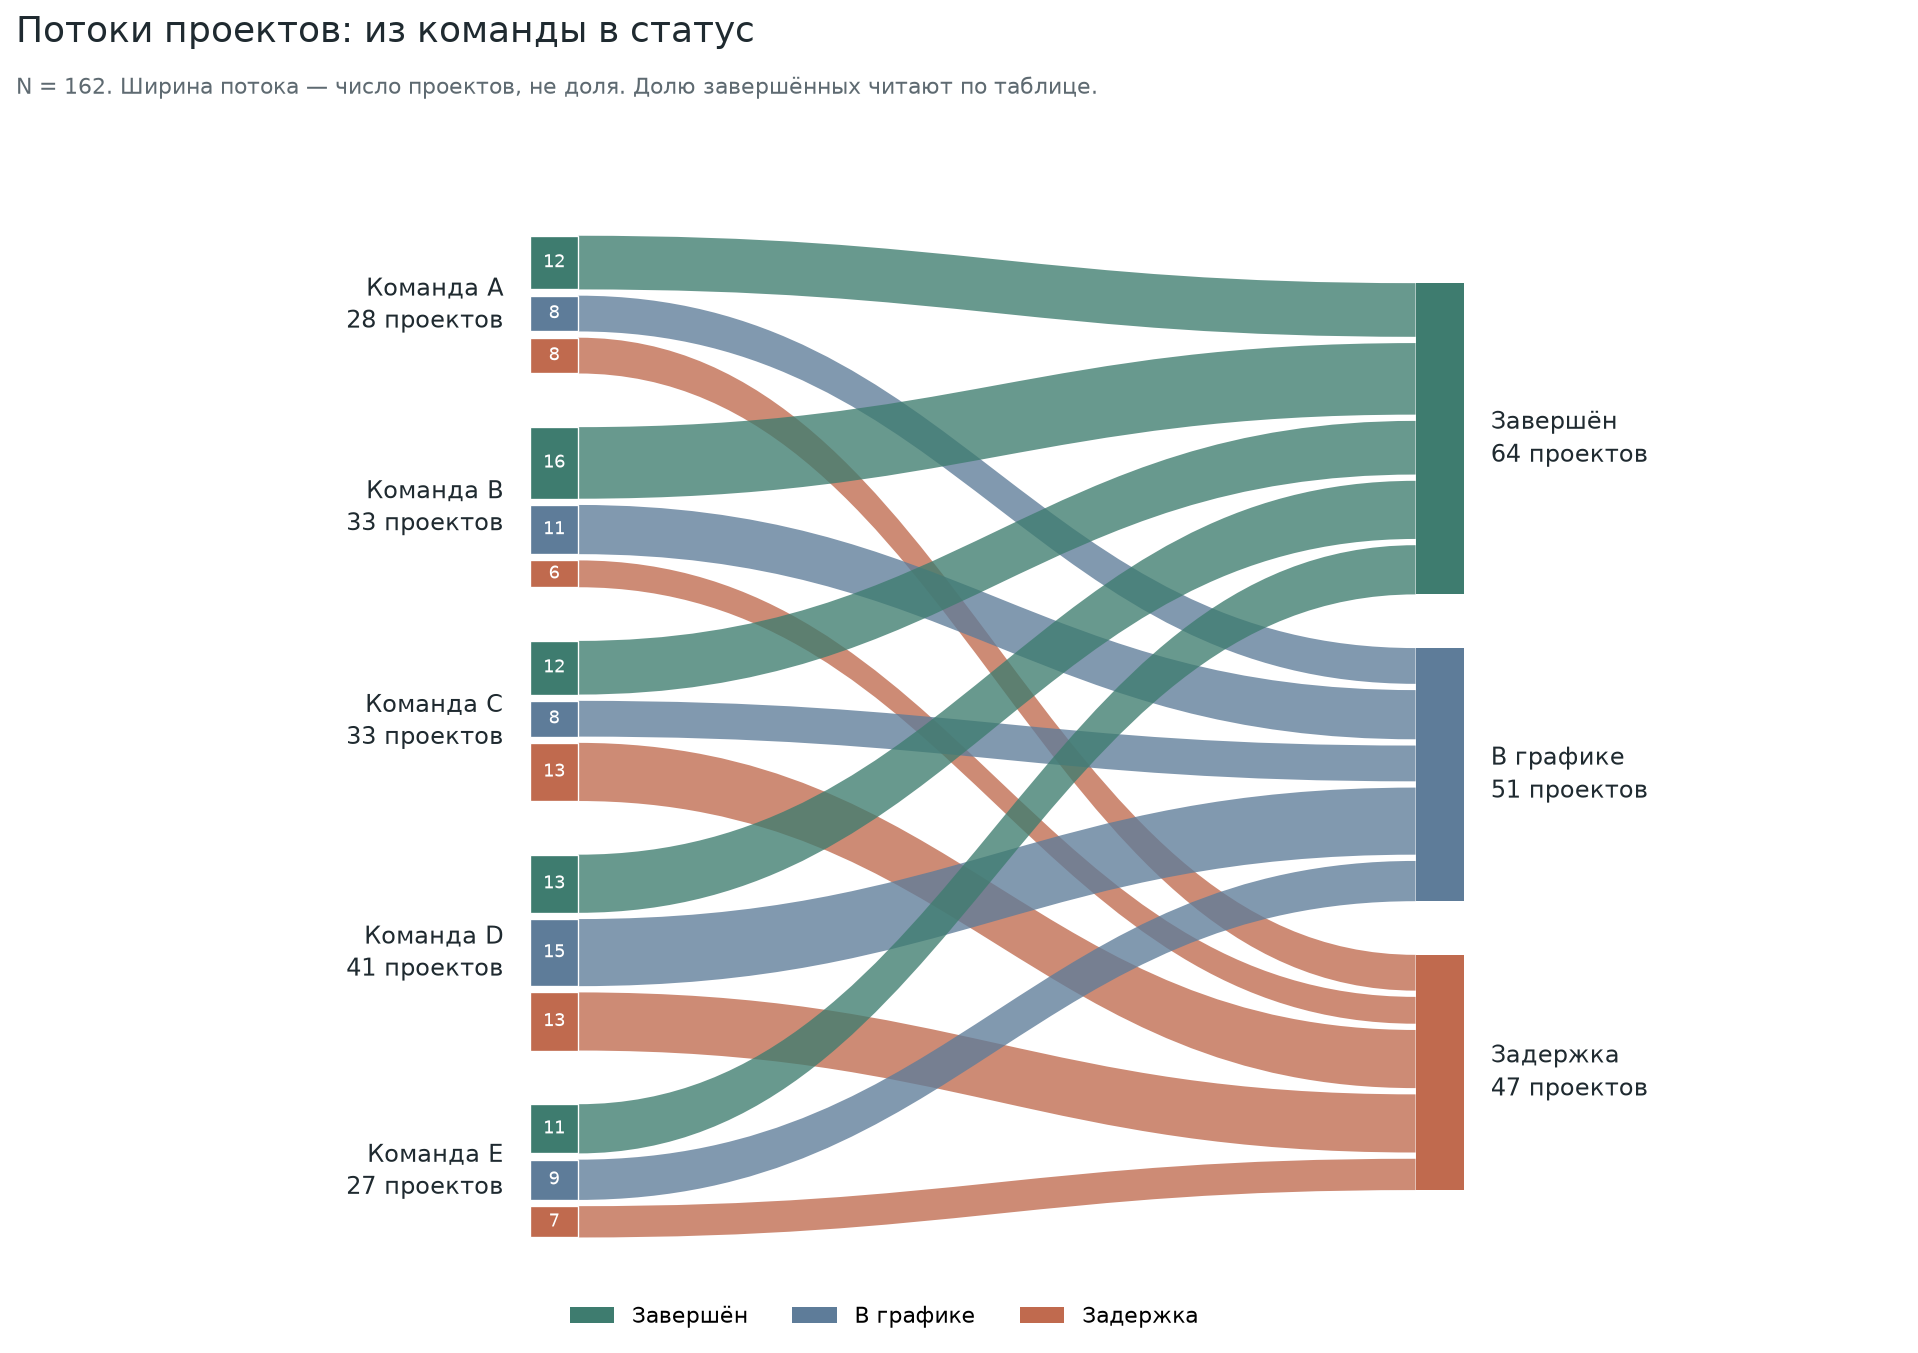

In [4]:
# Тот же alluvial, что описан для RAWGraphs: команда -> статус, ширина = project_count, цвет = статус.
# Это не столбчатая, не линейная и не круговая диаграмма: лента соединяет узел команды с узлом статуса.

import urllib.request
from matplotlib.path import Path as MplPath
from matplotlib.patches import PathPatch, Rectangle, Patch
import matplotlib.pyplot as plt

try:
    with urllib.request.urlopen("https://app.rawgraphs.io", timeout=12) as response:
        print(f"RAWGraphs ответил кодом {response.status}.")
    print(
        "Сайт открывается, но PNG он отдаёт только после ручной загрузки CSV в браузере. "
        "Ниже собран тот же поток из agg_team_status.csv, с тем же порядком и тем же размером."
    )
except Exception as error:
    print(f"RAWGraphs из ноутбука недоступен ({type(error).__name__}: {error}).")
    print("Ниже собран тот же alluvial по файлу agg_team_status.csv.")

source = pd.read_csv(OUT_DIR / "agg_team_status.csv")
colors = {"Завершён": "#3E7C6F", "В графике": "#5E7C99", "Задержка": "#C06A4E"}
count_of = {
    (row.Team, row.StatusRu): int(row.project_count)
    for row in source.itertuples(index=False)
}

def project_count(team, status):
    return count_of.get((team, status), 0)

def layout_up(groups, inners, getter):
    # Стек растёт снизу вверх. Кто передан в списке первым, тот оказывается снизу.
    cursor = 0.0
    nodes, flows = {}, {}
    inner_gap = 1.4
    group_gap = 12.0
    for group in groups:
        items = [(key, getter(group, key)) for key in inners if getter(group, key) > 0]
        low = cursor
        for index, (key, count) in enumerate(items):
            flows[(group, key)] = (cursor, cursor + count)
            cursor += count
            if index < len(items) - 1:
                cursor += inner_gap
        nodes[group] = (low, cursor)
        cursor += group_gap
    total = cursor - group_gap
    return nodes, flows, total

def shift(nodes, flows, total, target_mid):
    delta = target_mid - total / 2
    nodes = {key: (low + delta, high + delta) for key, (low, high) in nodes.items()}
    flows = {key: (low + delta, high + delta) for key, (low, high) in flows.items()}
    return nodes, flows

# A сверху, внутри команды сверху «Завершён». Справа сверху тоже «Завершён», внутри него сверху команда A.
left_nodes, left_flows, left_total = layout_up(
    list(reversed(TEAM_ORDER)),
    list(reversed(STATUS_ORDER)),
    lambda team, status: project_count(team, status),
)
right_nodes, right_flows, right_total = layout_up(
    list(reversed(STATUS_ORDER)),
    list(reversed(TEAM_ORDER)),
    lambda status, team: project_count(team, status),
)
target_mid = max(left_total, right_total) / 2
left_nodes, left_flows = shift(left_nodes, left_flows, left_total, target_mid)
right_nodes, right_flows = shift(right_nodes, right_flows, right_total, target_mid)

fig = plt.figure(figsize=(13.4, 8.6), dpi=160, facecolor="white")
ax = fig.add_axes([0.06, 0.06, 0.88, 0.78])
ax.set_facecolor("white")
x_left, x_right, node_width = 0.0, 1.0, 0.055

def ribbon(y_left_high, y_left_low, y_right_high, y_right_low, color):
    start = x_left + node_width
    end = x_right
    bend_left = start + (end - start) * 0.45
    bend_right = start + (end - start) * 0.55
    vertices = [
        (start, y_left_high),
        (bend_left, y_left_high),
        (bend_right, y_right_high),
        (end, y_right_high),
        (end, y_right_low),
        (bend_right, y_right_low),
        (bend_left, y_left_low),
        (start, y_left_low),
        (start, y_left_high),
    ]
    codes = [
        MplPath.MOVETO,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.LINETO,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.CURVE4,
        MplPath.CLOSEPOLY,
    ]
    ax.add_patch(
        PathPatch(
            MplPath(vertices, codes),
            facecolor=color,
            edgecolor="none",
            alpha=0.78,
            linewidth=0,
            zorder=1,
        )
    )

for team in TEAM_ORDER:
    for status in STATUS_ORDER:
        if (team, status) not in left_flows:
            continue
        left_low, left_high = left_flows[(team, status)]
        right_low, right_high = right_flows[(status, team)]
        ribbon(left_high, left_low, right_high, right_low, colors[status])

for team, (low, high) in left_nodes.items():
    total = sum(project_count(team, status) for status in STATUS_ORDER)
    for status in STATUS_ORDER:
        if (team, status) not in left_flows:
            continue
        band_low, band_high = left_flows[(team, status)]
        ax.add_patch(
            Rectangle(
                (x_left, band_low),
                node_width,
                band_high - band_low,
                facecolor=colors[status],
                edgecolor="white",
                linewidth=0.6,
                zorder=3,
            )
        )
        if band_high - band_low >= 5:
            ax.text(
                x_left + node_width / 2,
                (band_low + band_high) / 2,
                str(project_count(team, status)),
                ha="center",
                va="center",
                color="white",
                fontsize=8,
                zorder=4,
            )
    ax.text(
        x_left - 0.03,
        (low + high) / 2,
        f"Команда {team}\n{total} проектов",
        ha="right",
        va="center",
        fontsize=11,
        color="#1F2A30",
        linespacing=1.35,
    )

for status, (low, high) in right_nodes.items():
    ax.add_patch(
        Rectangle(
            (x_right, low),
            node_width,
            high - low,
            facecolor=colors[status],
            edgecolor="none",
            zorder=3,
        )
    )
    total = sum(project_count(team, status) for team in TEAM_ORDER)
    ax.text(
        x_right + node_width + 0.03,
        (low + high) / 2,
        f"{status}\n{total} проектов",
        ha="left",
        va="center",
        fontsize=11,
        color="#1F2A30",
        linespacing=1.35,
    )

ax.set_xlim(-0.58, 1.55)
ax.set_ylim(-6, max(left_total, right_total) + 10)
ax.axis("off")
legend = ax.legend(
    handles=[Patch(facecolor=colors[status], edgecolor="none", label=status) for status in STATUS_ORDER],
    loc="upper center",
    bbox_to_anchor=(0.46, -0.02),
    ncol=3,
    frameon=False,
    fontsize=10,
)
n_clean = int(source["project_count"].sum())
fig.text(
    0.06,
    0.955,
    "Потоки проектов: из команды в статус",
    fontsize=16,
    color="#1F2A30",
    ha="left",
    va="center",
)
fig.text(
    0.06,
    0.915,
    f"N = {n_clean}. Ширина потока — число проектов, не доля. Долю завершённых читают по таблице.",
    fontsize=10,
    color="#5E6A71",
    ha="left",
    va="center",
)

PNG_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(PNG_PATH, dpi=160, bbox_inches="tight", facecolor="white")
fig.savefig(SVG_PATH, bbox_inches="tight", facecolor="white")
print(f"PNG: {PNG_PATH}")
print(f"SVG: {SVG_PATH}")
plt.show()


## 4. Почему остаётся поток, а не два других типа

Для того чтобы выбор типа был аргументом, а не вкусом, рядом с потоком названы ещё два допустимых типа. Оба отвечают на соседние вопросы и хуже держат гипотезу о доле завершённых у C.

| Тип | Переменные | Что было бы видно | Ограничение |
| --- | --- | --- | --- |
| Alluvial, его и строим | Команда, статус, число проектов | Куда расходится портфель каждой команды и какой статус забирает объём | Ширина — объём. Долю завершённых по одной ленте не читают, для доли рядом стоит таблица. Потока во времени нет: у проекта один статус, а не история переходов. |
| Treemap, не строим | Те же, площадь — число проектов | Кто занимает большую площадь портфеля | Площади труднее сравнивать, чем ленты. Крупная команда снова выглядит успешнее за счёт размера. Доля C на прямоугольниках читается ещё хуже. |
| Parallel Coordinates, не строим | Число проектов, доля задержки, доля завершённых, медианы длины и бюджета | Профиль команды и гипотеза о загрузке | Пять ломаных выглядят точнее, чем позволяет число команд. Состав из трёх статусов сжимается в две доли, и пропадает ответ, куда делись проекты. |

Поток остаётся, потому что гипотеза 2 — про то, как портфель команды делится между закрытием и другими статусами. Прямоугольники прячут сравнение, параллельные координаты подменяют его профилем средних. Объём на потоке оставлен сознательно: руководителю нужно и число работ. Долю держит таблица долей.


## 5. Как читать рисунок и что делать руководителю

Чтобы проверить гипотезу, рисунок и таблица долей читаются вместе. Сначала видно, какая команда просто шире: это D, у неё 41 проект из 162. Ширина здесь объём портфеля. Затем видно, как внутри каждой команды сложены три полосы. Зелёная — завершённые, синяя — в графике, тёплая — задержка. Справа те же цвета собираются в три узла: завершено 64 проекта, в графике 51, с задержкой 47.

У команды C зелёная полоса — 12 из 33, это 36,4%. У остальных вместе завершено 52 из 129, это 40,3%. Выше всех команда B: 16 из 33, 48,5%. Ниже всех D: 13 из 41, 31,7%. C не первая, и разрыв с остальными не в её пользу. Порог «выше каждой команды и не меньше чем на 5 пунктов» не взят.

Вердикт по гипотезе 2: гипотеза не подтверждается. Очередь работ, которые нужно довести до закрытия, за командой C не закрепляется. На рисунке это видно ещё и так: у C тёплая полоса задержки (13) толще зелёной полосы закрытия (12). У B при том же размере портфеля задержка самая тонкая, 6 проектов.

Три вывода для решения.

Факт по выбранной гипотезе. Доля закрытых проектов у C не выше, чем у других команд. При том же числе работ, 33, команда B закрывает 48,5%, а C — 36,4%. Правило «закрытие отдаём C» на этом портфеле не на чем держать.

Граница причины. Файл не содержит ни стажа команды, ни типа проекта, ни причины задержки. Разница долей может быть и составом работ, и тем, как проставляют статус. Вывод такой: по этим статусам C не лидирует. Вывод «C работает хуже» из файла не следует.

Что делать с остальными гипотезами, их рисунком не строили, но пороги уже применены к тем же 162 строкам.

Команда A не чаще остальных укладывается в срок. У A в срок 20 из 28, это 71,4%. У остальных 95 из 134, это 70,9%. Разрыв около 0,5 пункта при пороге 5. Выше всех B, 81,8%. Гипотеза 1 не подтверждается. Жёсткие по сроку проекты на A не перекладываем.

Задержка не сидит в заметно большем бюджете. Медиана задержки 158 136 против 150 180 у остальных, разрыв 7 956 при пороге около 15 019. Среднее задержки 146 581 и ниже среднего остальных, 149 447. Выше по среднему бюджет у проектов в графике, 156 800. Гипотеза 3 не подтверждается. Контроль срыва не ограничиваем крупной суммой.

Длительность с бюджетом по всему портфелю не связана: Пирсон 0,0004, Спирмен 0,0056. Гипотеза 4 не подтверждается, смету по длине не прикидываем. Отдельно, и только внутри уже задержанных, Пирсон равен −0,327: более длинная задержка здесь не означает более дорогой проект. На весь портфель это правило не переносится.

Большая загрузка не показывает худший результат. Спирмен числа проектов и доли задержки 0,410 при пороге 0,5. У D больше всех работ, 41, и задержка 31,7%. У E меньше всех, 27, и задержка 25,9%. У B и C работ поровну, 33, а задержка 18,2% и 39,4%. Гипотеза 5 не подтверждается. Снимать проекты с D только потому, что их 41, эти данные не предлагают.


## Выводы

В ходе выполнения работы мы изучили портфель из 162 проектов пяти команд. У каждой строки есть длительность, бюджет и один из трёх статусов: завершён, в графике или с задержкой. Дат плана и факта в файле нет, поэтому «в срок» мы читали как отсутствие статуса задержки, а «завершён» — только как статус Completed.

Мы подготовили данные правилами методички: дубликаты кода, пропуски, чужие метки, нечисловые и неположительные длительность и бюджет. Пропуски не заполняли и хвост по усам Тьюки не отсекали: отдельного кластера в файле нет. Ни одно правило не сняло ни одной строки, рабочий набор остался из 162 проектов. Для рисунка мы собрали агрегат «команда × статус» с числом проектов, суммой бюджета и медианой длительности. Имена столбцов записаны без пробелов.

Мы выбрали одну комплексную диаграмму — поток из команды в статус. Объём ленты — число проектов, цвет — статус. Рядом оставили таблицу долей, потому что команды разного размера и толщина ленты сама по себе долю не показывает. Treemap и параллельные координаты мы разобрали как альтернативы и не строили: первый прячет сравнение долей в площадях, вторые отвечают на профиль команды, а не на состав статусов.

Полученные результаты показали, что ни одна из пяти гипотез не подтверждается по заранее заданным порогам. Команда C не лидирует по доле закрытых проектов, команда A почти не отличается от остальных по доле «в срок», бюджет задержки не отделён от остальных на заметную величину, длина проекта не заменяет смету, а большее число проектов не тянет за собой худшую долю задержки. Для руководителя это значит: не закреплять закрытие за C, не перекладывать жёсткие сроки на A, не ограничивать контроль срыва крупным бюджетом, не оценивать деньги по длительности и не снимать работы с D только из-за размера очереди. Смотреть нужно долю задержки и долю закрытия по каждой команде, держа рядом число проектов.
